In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# ДЗ 3. Динамічне програмування: планування обчислювальних потужностей

Варіант 1 -- трек A

Виконав: Олег Басистий

## 1. Постановка

### Опис системи

Організація отримує на плановий період $R = 8$ одиниць обчислювального ресурсу, і розподіляє їх між трьома напрямами:

- API -- обслуговування зовнішніх запитів клієнтів;
- аналітика -- звітні та аналітичні задачі;
- фонові задачі -- черги, пакетна обробка, обслуговування даних.

Кожному напряму можна виділити ціле число одиниць від 0 до 5. Ефект від $r$ одиниць задано таблицею корисності $g_k(r)$ в умовних балах. Кредити не переносяться на наступний період, тому весь ресурс має бути розподілено.

Стейкхолдер: власник ІТ-системи (платформна команда), який затверджує квоти compute credits для команд напрямів.

### Запитання, на яке відповідає модель

Скільки одиниць ресурсу виділити кожному напряму, щоб сумарний ефект був максимальним за повного використання $R = 8$? Як зміниться оптимальний розподіл і скільки додає кожна додаткова одиниця бюджету, якщо $R$ змінюється від 6 до 10?

### Прогноз до обчислень

*Записано до обчислень, після запуску не редагувався.*

Граничні ефекти $\Delta g_k(r) = g_k(r) - g_k(r - 1)$, бали за $r$-ту одиницю:

| Напрям | 1-ша | 2-га | 3-тя | 4-та | 5-та |
|---|---|---|---|---|---|
| API | 6 | 6 | 5 | 3 | 2 |
| аналітика | 6 | 6 | 4 | 2 | 2 |
| фонові задачі | 10 | 10 | 8 | 7 | 5 |

1. Перші одиниці фонових задач дають 10 балів проти 6 в API та аналітиці, і навіть 4-та одиниця фонових (7) краща за будь-яку одиницю інших напрямів. Тому фонові задачі отримають найбільшу частку, щонайменше 4 одиниці.
2. 5-та одиниця фонових дає лише 5 < 6, тож за $R = 8$ вигідніше віддати решту 4 одиниці API та аналітиці, які мають однакові перші дві одиниці (6, 6). Очікувана структура -- $(2;\ 2;\ 4)$, приблизно $10+10+8+7+4 \cdot 6 = 59$ балів.
3. Для $R = 10$ дві додаткові одиниці підуть туди, де наступна одиниця дає 5 -- 3-тя одиниця API і 5-та фонових. Очікую $(3;\ 2;\ 5)$ і приріст близько $+10$. Гранична цінність ресурсу спадає: 6, 6, 5, 5 балів за одиницю.
4. Інтуїтивне правило «віддати все напряму з найбільшим загальним ефектом» (фонові, $g_3(5) = 40$) програє, бо витрачає одиницю на 5-ту одиницю фонових (5 балів) замість 2-ї одиниці аналітики (6 балів).

Прогноз спирається на те, що граничні ефекти спадають.

## 2. Паспорт моделі

| Елемент | Позначення | Зміст | Одиниці | Джерело |
|---|---|---|---|---|
| Напрями (етапи) | $k = 1, 2, 3$ | 1 -- API, 2 -- аналітика, 3 -- фонові задачі | -- | умова варіанта |
| Ресурс | $R$ | бюджет періоду: база $R = 8$, сценарій $R + 2 = 10$, діапазон $6..10$ | compute credits | умова варіанта; у реальності -- бюджет або квота хмари |
| Межа на напрям | $r_{max} = 5$ | найбільше вкладення в один напрям; таблиця визначена лише для $r \le 5$ | compute credits | умова варіанта |
| Корисність | $g_k(r)$ | синтетичний ефект $r$ одиниць у напрямі $k$, $g_k(0) = 0$ | умовні бали | таблиця варіанта; у реальності -- навантажувальні тести |
| Керовані змінні | $r_1, r_2, r_3$ | скільки одиниць отримує напрям; цілі, $0 \le r_k \le 5$ | compute credits | рішення власника системи |
| Стан | $(k, s)$ | розглянуто перші $k$ напрямів, їм віддано рівно $s$ одиниць, $s = 0..R$ | compute credits | -- |
| Значення стану | $F_k(s)$ | найбільший сумарний ефект розподілу рівно $s$ одиниць між першими $k$ напрямами | умовні бали | -- |
| Критерій | $W = \sum_k g_k(r_k)$ | сумарний ефект, **max** | умовні бали | -- |
| Обмеження | $\sum_k r_k = R$, $r_k \in \{0, \dots, 5\}$ | увесь ресурс розподілено, межі вкладення | -- | -- |



### Формальна модель

$$\max_{r_1, r_2, r_3}\; W(r) = g_1(r_1) + g_2(r_2) + g_3(r_3) \quad \text{[умовні бали]}$$

за обмежень

$$
\begin{aligned}
r_1 + r_2 + r_3 &= R && \text{(увесь ресурс розподілено)}\\
r_k &\in \{0, 1, \dots, 5\}, && k = 1, 2, 3.
\end{aligned}
$$

Задача допустима лише за $0 \le R \le 3 \cdot 5 = 15$. Цільова функція -- сума функцій від окремих змінних, а обмеження -- одна рівність на суму. 

### Метрика системи, якій відповідає бал $g_k(r)$

Бал -- пропускна здатність у межах SLA -- кількість запитів або задач за годину, оброблених із затримкою p95 не вище цільової. Цю метрику можна виміряти тестом для кожного напряму і кожного $r$.

Без калібрування бал не можна читати як мілісекунди, гроші чи відсотки SLA:

- шкала умовна й різна між напрямами. 10 балів фонових задач і 10 балів API можуть відповідати зовсім різній кількості операцій і різній бізнес-цінності, тож потрібен перерахунок в одну шкалу, наприклад у гроші через ціну запиту або штраф за порушення SLA;
- модель додає бали напрямів. Мілісекунди затримки різних сервісів чи відсотки SLA не додаються, а гроші додаються лише після переведення кожного ефекту в гроші;
- залежність між балом і реальною метрикою не обов'язково лінійна, наприклад p95 різко зростає біля насичення.

Для застосування моделі в робочій системі потрібні: виміри throughput і p95/p99 затримки для кожного напряму залежно від кількості кредитів, профіль навантаження за періодом, вартість одиниці кредиту, ціна запиту та штрафи SLA.



### Припущення

1. Ефекти напрямів незалежні й аддитивні, тобто немає спільного вузького місця, через яке ресурс одного напряму впливав би на ефект іншого.
2. $g_k(r)$ детерміновані й відомі на весь період, навантаження всередині періоду стале.
3. Ресурс неподільний, і виділяється лише цілими кредитами.
4. Таблиця визначена тільки для $0 \le r \le 5$, і продовжувати її останнім приростом не можна.
5. Вартість самих кредитів не входить у критерій, бо бюджет $R$ уже виділено й невикористані кредити згорають.

## 3. Алгоритм: динамічне програмування за Беллманом

### Етапи, стани, переходи

- Етап $k = 1, 2, 3$ -- додаємо напрям $k$ (порядок: API, аналітика, фонові задачі).
- Стан $(k, s)$, $s = 0..R$ -- першим $k$ напрямам віддано рівно $s$ одиниць.
- Керування на етапі $k$ -- $r_k \in \{0, \dots, \min(5, s)\}$, і перехід $(k - 1,\ s - r_k) \to (k,\ s)$.
- Рекурентне співвідношення:

$$F_k(s) = \max_{0 \le r \le \min(5,\, s)} \{F_{k-1}(s - r) + g_k(r)\}, \qquad d_k(s) = \arg\max_r \{\dots\}.$$

- Граничні умови: $F_0(0) = 0$, а $F_0(s) = -\infty$ для $s > 0$, бо нерозподілений ресурс не допускається.
- Недопустимі стани: $F_k(s) = -\infty$, якщо $s > 5k$ (наприклад, $F_1(6), F_1(7), F_1(8)$, адже один напрям не вміщує понад 5 одиниць). Переходи з таких станів пропускаються, а $d_k(s)$ для них не визначене.
- Відповідь: $W^* = F_3(R)$. Розподіл відновлюємо зворотним ходом: $r_3 = d_3(R)$, $r_2 = d_2(R - r_3)$, $r_1 = d_1(R - r_3 - r_2)$.


### Чому алгоритм коректний

Після обробки етапу $k$ для кожного $s$ значення $F_k(s)$ дорівнює максимуму $\sum_{i \le k} g_i(r_i)$ серед усіх допустимих $(r_1, \dots, r_k)$ із сумою $s$ (або $-\infty$, якщо таких немає).

Доведення індукцією за $k$.   

Для $k = 0$ існує лише порожній розподіл суми 0.   

Нехай інваріант виконано для $k - 1$. Будь-який допустимий розподіл суми $s$ між першими $k$ напрямами має якесь $r_k = r \le \min(5, s)$, а його решта розподіляє $s - r$ між першими $k - 1$ напрямами, тож має ефект не більший за $F_{k-1}(s - r)$. Отже, ефект не перевищує $F_{k-1}(s - r) + g_k(r)$. Рекурсія перебирає всі $r$, і для кожного досягає цієї межі на оптимальному розподілі $s - r$. Це принцип оптимальності Беллмана: частина оптимального розподілу оптимальна для своєї підзадачі, бо ціль адитивна, а підзадачі пов'язані лише через $s$.

Алгоритм точний, бо не відкидає жодного значення $r_k$, і не потребує опуклості чи монотонності $g_k$.

### Псевдокод

```
F[0][0] = 0;  F[0][s] = -inf for s > 0
for k = 1..K:
    for s = 0..R:
        F[k][s] = -inf;  d[k][s] = none
        for r = 0..min(r_max, s):
            if F[k-1][s-r] == -inf: continue        # infeasible predecessor
            v = F[k-1][s-r] + g_k(r)
            if v > F[k][s]:                         # strict '>' : smallest r wins a tie
                F[k][s] = v;  d[k][s] = r
s = R
for k = K..1:  r_k = d[k][s];  s = s - r_k          # backward recovery
```

### Правило нічиїх

Значення $r$ у кожному стані перебираються за зростанням, і рекорд оновлюється лише за строгої нерівності. Отже, $d_k(s)$ -- **найменше** $r$, що дає максимум. За зворотного ходу це означає, що за рівноцінних варіантів пізніший етап (спочатку фонові задачі, потім аналітика) отримує мінімум, а залишок іде раніше розглянутим напрямам. Для $R = 8$ і $R = 10$ оптимум єдиний, і правило на відповідь не впливає. Для $R = 6, 7, 9$ існує кілька оптимумів (розділ 7), і правило робить вибір відтворюваним.

### Складність

- Станів $K(R + 1)$, для кожного не більше $r_{max} + 1$ переходів.
- Час $O(K \cdot R \cdot r_{max})$, пам'ять $O(K \cdot R)$ для таблиць $F$ і $d$. Таблиця $d$ потрібна саме для відновлення рішення, без неї лишилося б тільки значення.
- Для $R = 8$: $3 \cdot 9 = 27$ станів і $3 \cdot (1+2+3+4+5+6+6+6+6) = 117$ переглянутих переходів. Повний перебір переглядає $(r_{max} + 1)^K = 6^3 = 216$ трійок, а в загальному випадку його складність $O((r_{max} + 1)^K)$ зростає експоненційно за кількістю напрямів, тоді як ДП -- лінійно.

## 4. Реалізація

Усі функції отримують дані через аргументи: таблицю `gains` ($g_k(r)$ по рядках) і ресурс `R`. Кількість напрямів $K$ і $r_{max}$ визначаються з розміру таблиці, тому глобальних даних функції не використовують. Допоміжні функції порівняння, перевірки та побудови графіків так само отримують набір правил, контрольне значення і вісь бюджетів аргументами.

In [2]:
DIRECTIONS = ["API", "analytics", "background"]
GAINS = np.array([[0, 6, 12, 17, 20, 22],     # g_1(r): API
                  [0, 6, 12, 16, 18, 20],     # g_2(r): analytics
                  [0, 10, 20, 28, 35, 40]])   # g_3(r): background jobs, utility points

R_BASE = 8
R_SCENARIO = R_BASE + 2
R_RANGE = list(range(R_BASE - 2, R_BASE + 3))  # 6..10
CONTROL = {R_BASE: 59, R_SCENARIO: 69}         # teacher's control values

K, R_MAX = GAINS.shape[0], GAINS.shape[1] - 1

In [3]:
gains_table = pd.DataFrame(GAINS, index=DIRECTIONS, columns=[f"r={r}" for r in range(R_MAX + 1)])
print("g_k(r), utility points:")
display(gains_table)

g_k(r), utility points:


,r=0,r=1,r=2,r=3,r=4,r=5
API,0,6,12,17,20,22
analytics,0,6,12,16,18,20
background,0,10,20,28,35,40


In [4]:
marginal_table = pd.DataFrame(np.diff(GAINS, axis=1), index=DIRECTIONS,
                              columns=[f"unit {r}" for r in range(1, R_MAX + 1)])
print("marginal effect g_k(r) - g_k(r-1), utility points:")
display(marginal_table)

marginal effect g_k(r) - g_k(r-1), utility points:


,unit 1,unit 2,unit 3,unit 4,unit 5
API,6,6,5,3,2
analytics,6,6,4,2,2
background,10,10,8,7,5


In [5]:
def bellman(gains, R):
    """
    Forward Bellman pass
    """
    gains = np.asarray(gains)
    n_dir, r_max = gains.shape[0], gains.shape[1] - 1
    F = np.full((n_dir + 1, R + 1), -np.inf)
    D = np.full((n_dir + 1, R + 1), -1, dtype=int)
    F[0, 0] = 0
    work = {"states": 0, "feasible states": 0, "transitions": 0, "evaluated transitions": 0}
    for k in range(1, n_dir + 1):
        for s in range(R + 1):
            work["states"] += 1
            for r in range(min(r_max, s) + 1):
                work["transitions"] += 1
                prev = F[k - 1, s - r]
                if prev == -np.inf: 
                    continue
                work["evaluated transitions"] += 1
                value = prev + gains[k - 1, r]
                if value > F[k, s]:
                    F[k, s], D[k, s] = value, r
            work["feasible states"] += int(F[k, s] > -np.inf)
    return F, D, work

In [6]:
def recover(D, R):
    """
    Backward pass over the decision table
    """
    n_dir = D.shape[0] - 1
    alloc, trace, s = [0] * n_dir, [], R
    for k in range(n_dir, 0, -1):
        r = int(D[k, s])
        if r < 0:
            raise ValueError(f"state (k={k}, s={s}) is infeasible, R={R} cannot be allocated")
        alloc[k - 1] = r
        trace.append({"stage k": k, "state s": s, "decision r_k = d_k(s)": r, "next state s - r_k": s - r})
        s -= r
    assert s == 0, "recovery must end in the boundary state F_0(0)"
    return tuple(alloc), pd.DataFrame(trace)

In [7]:
def total_effect(gains, alloc):
    """
    W(r) = sum_k g_k(r_k)
    """
    return int(sum(gains[k][r] for k, r in enumerate(alloc)))

In [8]:
def solve(gains, R):
    """
    Bellman tables + recovered allocation for resource R
    """
    F, D, work = bellman(gains, R)
    value = F[-1, R]
    alloc, trace = recover(D, R) if value > -np.inf else (None, None)
    return {"R": R, "value": value, "alloc": alloc, "trace": trace, "F": F, "D": D, "work": work}

In [9]:
def stage_labels(directions):
    return ["k=0 (none)"] + [f"k={k} (+{name})" for k, name in enumerate(directions, start=1)]


def value_frame(F, directions):
    """
    F_k(s) as a table, -inf shown as '-inf'
    """
    t = pd.DataFrame(F, index=stage_labels(directions), columns=[f"s={s}" for s in range(F.shape[1])])
    return t.map(lambda v: "-inf" if v == -np.inf else int(v))


def decision_frame(D, directions):
    """
    d_k(s) as a table, undefined decisions (infeasible states and k=0) shown as '-'
    """
    t = pd.DataFrame(D, index=stage_labels(directions), columns=[f"s={s}" for s in range(D.shape[1])])
    return t.map(lambda v: "-" if v < 0 else int(v))

In [10]:
def transition_log(F, gains, k, s):
    """
    All candidates r for the state (k, s): F_{k-1}(s - r) + g_k(r); the chosen one is marked.
    """
    rows = []
    for r in range(min(len(gains[k - 1]) - 1, s) + 1):
        prev = F[k - 1, s - r]
        rows.append({"r_k": r, "s - r": s - r, "F_{k-1}(s-r)": prev, "g_k(r)": gains[k - 1][r],
                     "candidate": prev + gains[k - 1][r]})
    log = pd.DataFrame(rows)
    for col in ["F_{k-1}(s-r)", "candidate"]:
        log[col] = log[col].map(lambda v: "-inf" if v == -np.inf else int(v))
    numeric = pd.to_numeric(log["candidate"], errors="coerce").fillna(-np.inf)
    best = numeric.max()
    log["chosen"] = np.where(log.index == numeric.idxmax(), "<- max", "")  # idxmax = first = smallest r
    log["ties"] = np.where((numeric == best) & (log["chosen"] == ""), "tie", "")
    return log

## 5. Базовий результат, $R = 8$

In [11]:
base = solve(GAINS, R_BASE)

print(f"F_k(s), utility points, R = {R_BASE}:")
display(value_frame(base["F"], DIRECTIONS))

F_k(s), utility points, R = 8:


,s=0,s=1,s=2,s=3,s=4,s=5,s=6,s=7,s=8
k=0 (none),0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
k=1 (+API),0,6,12,17,20,22,-inf,-inf,-inf
k=2 (+analytics),0,6,12,18,24,29,33,36,38
k=3 (+background),0,10,20,28,35,41,47,53,59


In [12]:
print("d_k(s), units given to direction k in the best transition:")
display(decision_frame(base["D"], DIRECTIONS))

d_k(s), units given to direction k in the best transition:


,s=0,s=1,s=2,s=3,s=4,s=5,s=6,s=7,s=8
k=0 (none),-,-,-,-,-,-,-,-,-
k=1 (+API),0,1,2,3,4,5,-,-,-
k=2 (+analytics),0,0,0,1,2,2,3,3,3
k=3 (+background),0,1,2,3,4,4,4,4,4


In [13]:
print("work:", base["work"])

work: {'states': 27, 'feasible states': 24, 'transitions': 117, 'evaluated transitions': 78}


У рядку $k = 1$ стани $s = 6, 7, 8$ недопустимі ($-\infty$), бо один API не вміщує понад 5 одиниць. Від $k = 2$ усі стани допустимі. Рядок $k = 3$ -- це оптимальні значення для **будь-якого** бюджету $s \le 8$, тож одна таблиця вже дає відповідь і для $R = 6, 7$.

Обчислено 27 станів ($k = 1..3$, $s = 0..8$; рядок $k = 0$ -- граничні умови) і переглянуто 117 переходів. Недопустимі 3 стани, $F_1(6..8)$. Лише 78 переходів оцінено, а решту 39 відкинуто, бо вони вели з недопустимого стану (здебільшого з $F_0(s > 0)$).

Журнал переходів для фінального стану $(k = 3,\ s = 8)$ і зворотний хід:

In [14]:
display(transition_log(base["F"], GAINS, k=3, s=R_BASE))

,r_k,s - r,F_{k-1}(s-r),g_k(r),candidate,chosen,ties
0,0,8,38,0,38,,
1,1,7,36,10,46,,
2,2,6,33,20,53,,
3,3,5,29,28,57,,
4,4,4,24,35,59,<- max,
5,5,3,18,40,58,,


In [15]:
display(base["trace"])

,stage k,state s,decision r_k = d_k(s),next state s - r_k
0,3,8,4,4
1,2,4,2,2
2,1,2,2,0


In [16]:
alloc = base["alloc"]
print("optimal allocation:", dict(zip(DIRECTIONS, alloc)), "credits")
print(f"used {sum(alloc)} of R = {R_BASE} credits")
print(f"W* = F_3({R_BASE}) = {base['value']:.0f} points, recomputed from g: {total_effect(GAINS, alloc)} points")
assert sum(alloc) == R_BASE
assert total_effect(GAINS, alloc) == base["value"] == CONTROL[R_BASE]

optimal allocation: {'API': 2, 'analytics': 2, 'background': 4} credits
used 8 of R = 8 credits
W* = F_3(8) = 59 points, recomputed from g: 59 points


Оптимальний розподіл -- $r^* = (2;\ 2;\ 4)$: API 2 одиниці, аналітика 2, фонові задачі 4. Використано весь ресурс ($2 + 2 + 4 = 8$), $W^* = 12 + 12 + 35 = 59$ балів, що збігається з контрольним значенням викладача.

### Перевірка вручну

$F_3(8) = \max_{r_3} \{F_2(8 - r_3) + g_3(r_3)\} = \max\{38 + 0,\ 36 + 10,\ 33 + 20,\ 29 + 28,\ 24 + 35,\ 18 + 40\} = \max\{38, 46, 53, 57, \mathbf{59}, 58\} = 59$ при $r_3 = 4$.

Для залишку $s = 4$: $F_2(4) = \max\{F_1(4) + 0,\ F_1(3) + 6,\ F_1(2) + 12,\ F_1(1) + 16,\ F_1(0) + 18\} = \max\{20, 23, \mathbf{24}, 22, 18\} = 24$ при $r_2 = 2$. Тоді $r_1 = 4 - 2 = 2$, $F_1(2) = g_1(2) = 12$.

Друге місце -- $r_3 = 5$ (58 балів): 5-та одиниця фонових дає 5, а одиниця, забрана в API чи аналітики, коштує 6.

### Порівняння з базовими розв'язками

Порівнюємо оптимум ДП з трьома простими правилами, якими могла б скористатися людина без моделі:

- **жадібний вибір за загальним ефектом напряму** -- впорядкувати напрями за $g_k(5)$ і заповнювати кожен до межі 5 одиниць, поки не скінчиться ресурс;
- **рівний розподіл** -- по $\lfloor R/K \rfloor$ одиниць кожному, а залишок по одній першим напрямам;
- **жадібний за граничним ефектом** -- кожну наступну одиницю віддавати напряму з найбільшим $g_k(r_k + 1) - g_k(r_k)$ (при рівності -- напрям з меншим номером).

In [17]:
def greedy_by_total_effect(gains, R):
    """
    Rank directions by their full effect g_k(r_max), fill each up to r_max in that order.
    """
    gains = np.asarray(gains)
    n_dir, r_max = gains.shape[0], gains.shape[1] - 1
    order = sorted(range(n_dir), key=lambda k: (-gains[k, r_max], k))
    alloc, left = [0] * n_dir, R
    for k in order:
        alloc[k] = min(r_max, left)
        left -= alloc[k]
    return tuple(alloc)

In [18]:
def equal_split(gains, R):
    """
    R // K units to every direction, the remainder one by one to the first directions.
    """
    n_dir, r_max = len(gains), len(gains[0]) - 1
    alloc = [min(r_max, R // n_dir + (k < R % n_dir)) for k in range(n_dir)]
    return tuple(alloc)

In [19]:
def greedy_by_marginal(gains, R):
    """
    Give units one at a time to the direction with the largest next marginal effect.
    """
    gains = np.asarray(gains)
    n_dir, r_max = gains.shape[0], gains.shape[1] - 1
    alloc = [0] * n_dir
    for _ in range(R):
        open_dirs = [k for k in range(n_dir) if alloc[k] < r_max]
        k = max(open_dirs, key=lambda k: (gains[k, alloc[k] + 1] - gains[k, alloc[k]], -k))
        alloc[k] += 1
    return tuple(alloc)

In [20]:
BASELINES = {"greedy by total effect g_k(5)": greedy_by_total_effect,
             "equal split": equal_split,
             "greedy by marginal effect": greedy_by_marginal}


def compare_with_baselines(gains, R, opt, baselines):
    rows = [{"method": "Bellman DP (exact)", "allocation": opt["alloc"], "W": int(opt["value"])}]
    for name, rule in baselines.items():
        a = rule(gains, R)
        rows.append({"method": name, "allocation": a, "W": total_effect(gains, a)})
    t = pd.DataFrame(rows).set_index("method")
    t["sum r_k"] = t["allocation"].map(sum)
    t["gap to W*"] = t["W"] - int(opt["value"])
    t["gap, %"] = (100 * t["gap to W*"] / opt["value"]).round(1)
    return t

In [21]:
display(compare_with_baselines(GAINS, R_BASE, base, BASELINES))

,allocation,W,sum r_k,gap to W*,"gap, %"
method,,,,,
Bellman DP (exact),"(2, 2, 4)",59,8,0,0.0
greedy by total effect g_k(5),"(3, 0, 5)",57,8,-2,-3.4
equal split,"(3, 3, 2)",53,8,-6,-10.2
greedy by marginal effect,"(2, 2, 4)",59,8,0,0.0


Жадібний вибір за загальним ефектом бачить, що фонові задачі мають найбільший $g_3(5) = 40$, і віддає їм усі 5 одиниць, потім API ($g_1(5) = 22$) -- решту 3. Результат $(3;\ 0;\ 5)$ дає 57 балів, на 2 менше за оптимум. Правило порівнює напрями за ефектом **повного** вкладення, хоча вирішальними є граничні ефекти конкретних одиниць. 5-та одиниця фонових дає лише 5 балів, а 3-тя одиниця API -- 5, тоді як 1-ша і 2-га одиниці аналітики лишилися невикористаними (по 6). Тому цей вибір не є коректним алгоритмом: він не розглядає альтернативне використання одиниць, яке ДП перебирає явно. Рівний розподіл $(3;\ 3;\ 2)$ ще гірший, 53 бали ($-10{,}2$ %), бо недодає ресурсу найефективнішому напряму.

Жадібний вибір за граничним ефектом тут випадково збігся з оптимумом. Це наслідок даних варіанта, а не правила: усі $g_k$ увігнуті (граничні ефекти не зростають), а для увігнутих сепарабельних функцій таке правило оптимальне. Якщо ефект має поріг (наприклад, кешування чи нова репліка корисні лише від кількох одиниць), граничне правило помиляється. Нижче -- ілюстративний контрприклад (не дані варіанта).

In [22]:
concave = (np.diff(GAINS, n=2, axis=1) <= 0).all(axis=1)
print("marginal effects are non-increasing (g_k concave):", dict(zip(DIRECTIONS, concave.tolist())))

marginal effects are non-increasing (g_k concave): {'API': True, 'analytics': True, 'background': True}


In [23]:
# Illustrative counterexample with a threshold effect, not the variant data
CE_GAINS = np.array([[0, 1, 2, 9],    # direction A: useful only with 3 units
                     [0, 4, 7, 8]])   # direction B: diminishing returns
CE_R = 3
ce = solve(CE_GAINS, CE_R)
ce_table = compare_with_baselines(CE_GAINS, CE_R, ce, BASELINES)
display(ce_table)

,allocation,W,sum r_k,gap to W*,"gap, %"
method,,,,,
Bellman DP (exact),"(3, 0)",9,3,0,0.0
greedy by total effect g_k(5),"(3, 0)",9,3,0,0.0
equal split,"(2, 1)",6,3,-3,-33.3
greedy by marginal effect,"(1, 2)",8,3,-1,-11.1


Тут граничне правило двічі обирає напрям B (прирости 4 і 3), а третю одиницю за рівності 1 = 1 віддає першому за номером A, і отримує 8 балів. Оптимум $(3;\ 0)$ дає 9, бо ефект напряму A з'являється лише після трьох одиниць. ДП знаходить його, бо розглядає всі $r$ для кожного стану, а не лише наступну одиницю.

## 6. Експеримент: бюджет $R + 2 = 10$ і діапазон $R = 6..10$

Змінюється лише бюджет $R$. Таблиця $g_k(r)$, межа $r_{max} = 5$ і правило нічиїх ті самі.

In [24]:
scenario = solve(GAINS, R_SCENARIO)

print(f"F_k(s), utility points, R = {R_SCENARIO}:")
display(value_frame(scenario["F"], DIRECTIONS))

F_k(s), utility points, R = 10:


,s=0,s=1,s=2,s=3,s=4,s=5,s=6,s=7,s=8,s=9,s=10
k=0 (none),0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
k=1 (+API),0,6,12,17,20,22,-inf,-inf,-inf,-inf,-inf
k=2 (+analytics),0,6,12,18,24,29,33,36,38,40,42
k=3 (+background),0,10,20,28,35,41,47,53,59,64,69


In [25]:
print("d_k(s):")
display(decision_frame(scenario["D"], DIRECTIONS))

d_k(s):


,s=0,s=1,s=2,s=3,s=4,s=5,s=6,s=7,s=8,s=9,s=10
k=0 (none),-,-,-,-,-,-,-,-,-,-,-
k=1 (+API),0,1,2,3,4,5,-,-,-,-,-
k=2 (+analytics),0,0,0,1,2,2,3,3,3,4,5
k=3 (+background),0,1,2,3,4,4,4,4,4,4,5


In [26]:
display(transition_log(scenario["F"], GAINS, k=3, s=R_SCENARIO))

,r_k,s - r,F_{k-1}(s-r),g_k(r),candidate,chosen,ties
0,0,10,42,0,42,,
1,1,9,40,10,50,,
2,2,8,38,20,58,,
3,3,7,36,28,64,,
4,4,6,33,35,68,,
5,5,5,29,40,69,<- max,


In [27]:
display(scenario["trace"])

,stage k,state s,decision r_k = d_k(s),next state s - r_k
0,3,10,5,5
1,2,5,2,3
2,1,3,3,0


In [28]:
print("optimal allocation:", dict(zip(DIRECTIONS, scenario["alloc"])), "credits")
print(f"W* = {scenario['value']:.0f} points, work: {scenario['work']}")
assert sum(scenario["alloc"]) == R_SCENARIO
assert total_effect(GAINS, scenario["alloc"]) == scenario["value"] == CONTROL[R_SCENARIO]

optimal allocation: {'API': 3, 'analytics': 2, 'background': 5} credits
W* = 69 points, work: {'states': 33, 'feasible states': 28, 'transitions': 153, 'evaluated transitions': 93}


За $R = 10$ оптимум -- $(3;\ 2;\ 5)$, $W^* = 17 + 12 + 40 = 69$ балів (контрольне значення). Порівняно з базою дві нові одиниці отримали API (3-тя одиниця, +5) і фонові задачі (5-та одиниця, +5), а аналітика лишилася з 2 одиницями, бо її 3-тя одиниця дає лише 4. Зворотний хід: $d_3(10) = 5$, $d_2(5) = 2$, $r_1 = 3$.

Тепер розв'язуємо задачу окремо для кожного $R = 6..10$ і зводимо результати в одну таблицю.

In [29]:
experiment_rows, experiment_solutions = [], {}
for R in R_RANGE:
    sol = solve(GAINS, R)
    experiment_solutions[R] = sol
    experiment_rows.append({"R": R, "W*": int(sol["value"]),
                            **{f"r_{k + 1} {name}": sol["alloc"][k] for k, name in enumerate(DIRECTIONS)},
                            "states": sol["work"]["states"], "transitions": sol["work"]["transitions"]})

experiment = pd.DataFrame(experiment_rows).set_index("R")
w_prev = solve(GAINS, R_RANGE[0] - 1)["value"]
experiment["marginal value dW*/dR"] = experiment["W*"].diff().fillna(experiment["W*"].iloc[0] - w_prev).astype(int)
experiment["greedy by total effect"] = [total_effect(GAINS, greedy_by_total_effect(GAINS, R)) for R in R_RANGE]

In [30]:
display(experiment)

# a single run for R = 10 already contains F_3(s) for every s <= 10
assert np.array_equal(scenario["F"][-1, R_RANGE], experiment["W*"].to_numpy())

,W*,r_1 API,r_2 analytics,r_3 background,states,transitions,marginal value dW*/dR,greedy by total effect
R,,,,,,,,
6,47,2,0,4,21,81,6,46
7,53,2,1,4,24,99,6,52
8,59,2,2,4,27,117,6,57
9,64,3,2,4,30,135,5,60
10,69,3,2,5,33,153,5,62


In [31]:
API_COLOR, ANALYTICS_COLOR, BACKGROUND_COLOR = "#2a78d6", "#6250d6", "#1baf7a"
INK = "#52514e"
GREEDY_COLOR = "#e34948"
DIR_COLORS = [API_COLOR, ANALYTICS_COLOR, BACKGROUND_COLOR]

Rs = np.array(R_RANGE)


def finish_budget_axis(ax, title, budgets):
    """
    Shared styling of the budget experiment plots (only R changes, R = 6..10)
    """
    ax.set_title(title)
    ax.set_xticks(budgets)
    ax.set_xlabel("R, compute credits")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.show()

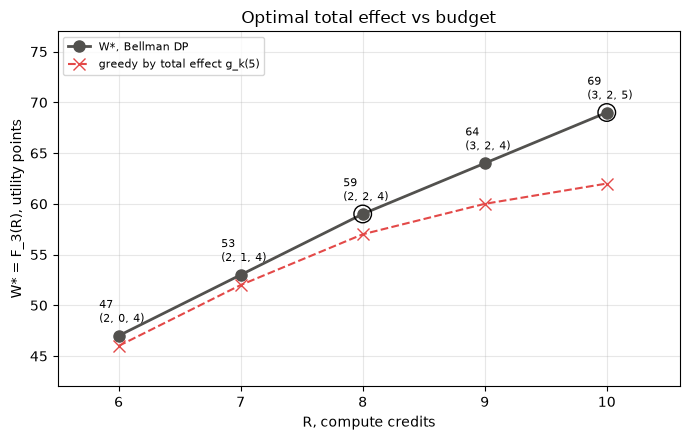

In [32]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(Rs, experiment["W*"], color=INK, lw=2, marker="o", ms=8, label="W*, Bellman DP")
ax.plot(Rs, experiment["greedy by total effect"], color=GREEDY_COLOR, lw=1.5, ls="--", marker="x", ms=8,
        label="greedy by total effect g_k(5)")
for R in R_RANGE:
    a = experiment_solutions[R]["alloc"]
    ax.annotate(f"{int(experiment.loc[R, 'W*'])}\n{a}", (R, experiment.loc[R, "W*"]),
                textcoords="offset points", xytext=(-14, 10), fontsize=8)
for R in [R_BASE, R_SCENARIO]:  # base R = 8 and R + 2 = 10
    ax.scatter(R, experiment.loc[R, "W*"], s=160, facecolors="none", edgecolors="black", zorder=4)
ax.set_ylim(experiment["greedy by total effect"].min() - 4, experiment["W*"].max() + 8)
ax.set_xlim(Rs[0] - 0.5, Rs[-1] + 0.6)
ax.set_ylabel("W* = F_3(R), utility points")
finish_budget_axis(ax, "Optimal total effect vs budget", Rs)

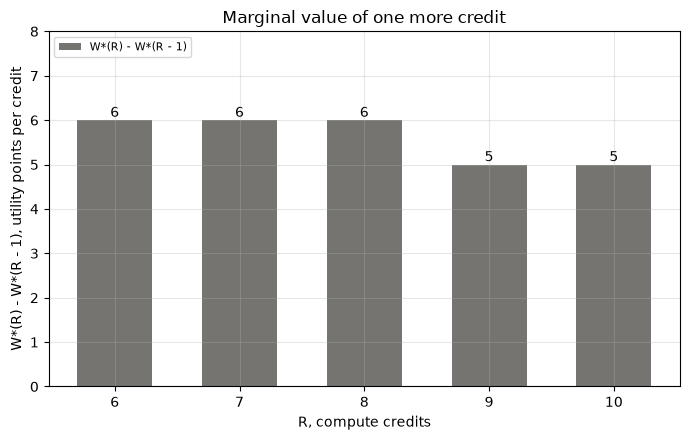

In [33]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(Rs, experiment["marginal value dW*/dR"], color=INK, alpha=0.8, width=0.6,
              label="W*(R) - W*(R - 1)")
ax.bar_label(bars, fmt="%d")
ax.set_ylim(0, experiment["marginal value dW*/dR"].max() + 2)
ax.set_ylabel("W*(R) - W*(R - 1), utility points per credit")
finish_budget_axis(ax, "Marginal value of one more credit", Rs)

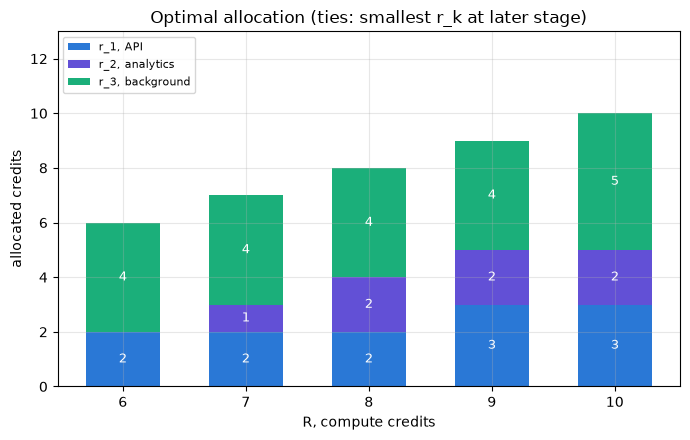

In [34]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bottom = np.zeros(len(Rs))
for k, name in enumerate(DIRECTIONS):
    vals = experiment[f"r_{k + 1} {name}"].to_numpy()
    ax.bar(Rs, vals, bottom=bottom, color=DIR_COLORS[k], width=0.6, label=f"r_{k + 1}, {name}")
    for x, b, v in zip(Rs, bottom, vals):
        if v:
            ax.text(x, b + v / 2, str(v), ha="center", va="center", color="white", fontsize=9)
    bottom += vals
ax.set_ylim(0, bottom.max() + 3)
ax.set_ylabel("allocated credits")
finish_budget_axis(ax, "Optimal allocation (ties: smallest r_k at later stage)", Rs)

- $W^*(R)$ зростає, але дедалі повільніше, бо гранична цінність кредиту спадає: 6, 6, 6, 5, 5 балів. Кожен новий кредит іде на найкращу ще не використану одиницю. До $R = 8$ це одиниці API та аналітики по 6 балів, а далі -- 3-тя одиниця API і 5-та одиниця фонових по 5. Наступний, 11-й кредит дав би лише 4 (3-тя одиниця аналітики).
- Перехід $8 \to 10$ додає $+10$ балів ($+16{,}9$ %), тоді як $6 \to 8$ додавав $+12$. Отже, додатковий бюджет корисний, але менш ефективний, ніж попередні кредити.
- Фонові задачі отримують 4 одиниці вже з $R = 6$ і досягають межі 5 лише при $R = 10$, а гнучкою частиною розподілу є API та аналітика.
- Для $R = 6, 7, 9$ є рівноцінні оптимуми (розділ 7), і на графіку показано вибір за правилом нічиїх. Наприклад, для $R = 9$ розподіли $(3;\ 2;\ 4)$ і $(2;\ 2;\ 5)$ дають однакові 64 бали.
- Жадібний вибір за загальним ефектом програє оптимуму при всіх $R$ з діапазону, і це ще раз показує, що правило некоректне.
- Обчислювальна робота зростає лінійно за $R$: $3(R + 1)$ станів і від 81 до 153 переходів. Один прохід для $R = 10$ дає весь рядок $F_3(s)$, $s = 0..10$, тому окремі запуски для $R = 6..9$ перевіряють, а не доповнюють його.

## 7. Верифікація

### Повний перебір

Незалежний метод перебирає всі $6^3 = 216$ трійок $(r_1, r_2, r_3) \in \{0..5\}^3$, залишає ті, де $\sum r_k = R$, і рахує ціль прямо з таблиці $g_k(r)$. Він не використовує таблиць $F$ і $d$, тому перевіряє і значення, і відновлений розподіл. Якщо оптимумів кілька, перебір повертає їх усі, і ми перевіряємо, що розподіл ДП є одним із них і саме тим, який задає правило нічиїх (найменше $r_3$, потім найменше $r_2$).

In [35]:
def brute_force(gains, R):
    """
    Enumerate every r in {0..r_max}^K with sum R; return the best value, all optimal allocations, counters.
    """
    n_dir, r_max = len(gains), len(gains[0]) - 1
    checked, feasible = 0, {}
    for alloc in itertools.product(range(r_max + 1), repeat=n_dir):
        checked += 1
        if sum(alloc) == R:
            feasible[alloc] = total_effect(gains, alloc)
    if not feasible:
        return -np.inf, [], checked, 0
    best = max(feasible.values())
    optima = sorted(a for a, v in feasible.items() if v == best)
    return best, optima, checked, len(feasible)

In [36]:
def tie_rule_choice(optima):
    """
    The optimum the DP tie rule must return: smallest r_K, then smallest r_{K-1}, ...
    """
    return min(optima, key=lambda a: a[::-1])

In [37]:
def verify(gains, R, sol, control=None):
    """
    Independent checks of a DP solution against brute force and the problem constraints.
    control -- known optimal value for this R, if any
    """
    r_max = len(gains[0]) - 1
    bf_value, bf_optima, checked, n_feasible = brute_force(gains, R)
    alloc = sol["alloc"]
    return {
        "R": R,
        "DP allocation": alloc,
        "brute-force optima": bf_optima,
        "triples checked": checked,
        "feasible triples": n_feasible,
        "0 <= r_k <= 5": all(0 <= r <= r_max for r in alloc),
        "sum r_k = R": sum(alloc) == R,
        "W(r) = F_3(R)": total_effect(gains, alloc) == sol["value"],
        "F_3(R) = brute max": sol["value"] == bf_value,
        "alloc is optimal": alloc in bf_optima,
        "alloc = tie rule": alloc == tie_rule_choice(bf_optima),
        "control value": control is None or control == sol["value"],
    }

In [38]:
verification = pd.DataFrame([verify(GAINS, R, experiment_solutions[R], CONTROL.get(R)) for R in R_RANGE]).set_index("R")
display(verification)

check_cols = ["0 <= r_k <= 5", "sum r_k = R", "W(r) = F_3(R)", "F_3(R) = brute max",
              "alloc is optimal", "alloc = tie rule", "control value"]
assert verification[check_cols].all().all()

,DP allocation,brute-force optima,triples checked,feasible triples,0 <= r_k <= 5,sum r_k = R,W(r) = F_3(R),F_3(R) = brute max,alloc is optimal,alloc = tie rule,control value
R,,,,,,,,,,,
6,"(2, 0, 4)","[(0, 2, 4), (1, 1, 4), (2, 0, 4)]",216,25,True,True,True,True,True,True,True
7,"(2, 1, 4)","[(1, 2, 4), (2, 1, 4)]",216,27,True,True,True,True,True,True,True
8,"(2, 2, 4)","[(2, 2, 4)]",216,27,True,True,True,True,True,True,True
9,"(3, 2, 4)","[(2, 2, 5), (3, 2, 4)]",216,25,True,True,True,True,True,True,True
10,"(3, 2, 5)","[(3, 2, 5)]",216,21,True,True,True,True,True,True,True


Для базового $R = 8$ і сценарію $R = 10$ оптимум єдиний, тому вимагаємо точної рівності значень **і** рішень. Додатково перевіряємо крайові випадки: нульовий бюджет, найбільший допустимий $R = 15$, недопустимий $R = 16$ (таблицю не можна продовжувати, тож розподілу немає) і контрприклад з порогом.

In [39]:
# base and scenario: unique optimum, equal value and equal allocation
for R, expected_alloc in [(R_BASE, (2, 2, 4)), (R_SCENARIO, (3, 2, 5))]:
    bf_value, bf_optima, _, _ = brute_force(GAINS, R)
    sol = experiment_solutions[R]
    assert bf_optima == [sol["alloc"]] == [expected_alloc], (R, bf_optima, sol["alloc"])
    assert sol["value"] == bf_value == CONTROL[R]
    print(f"R = {R:2d}: DP {sol['alloc']} = {sol['value']:.0f}, brute force {bf_optima[0]} = {bf_value}  OK")

R =  8: DP (2, 2, 4) = 59, brute force (2, 2, 4) = 59  OK
R = 10: DP (3, 2, 5) = 69, brute force (3, 2, 5) = 69  OK


In [40]:
# edge cases
zero = solve(GAINS, 0)
assert zero["alloc"] == (0, 0, 0) and zero["value"] == 0

full = solve(GAINS, K * R_MAX)
assert full["alloc"] == (R_MAX,) * K and full["value"] == GAINS[:, -1].sum()

over = solve(GAINS, K * R_MAX + 1)
assert over["value"] == -np.inf and over["alloc"] is None
assert brute_force(GAINS, K * R_MAX + 1)[3] == 0
try:
    recover(over["D"], K * R_MAX + 1)
    raise AssertionError("recovery must fail for an infeasible R")
except ValueError as e:
    print("R = 16:", e)

R = 16: state (k=3, s=16) is infeasible, R=16 cannot be allocated


In [41]:
# the threshold counterexample: DP still matches brute force, the marginal greedy does not
ce_bf_value, ce_bf_optima, _, _ = brute_force(CE_GAINS, CE_R)
assert ce["value"] == ce_bf_value == 9 and ce_bf_optima == [ce["alloc"]] == [(3, 0)]
assert total_effect(CE_GAINS, greedy_by_marginal(CE_GAINS, CE_R)) < ce["value"]

# the greedy by total effect is not optimal on the variant data
assert total_effect(GAINS, greedy_by_total_effect(GAINS, R_BASE)) < base["value"]

# base data were not modified by any experiment
assert np.array_equal(GAINS, [[0, 6, 12, 17, 20, 22], [0, 6, 12, 16, 18, 20], [0, 10, 20, 28, 35, 40]])
print("all checks passed")

all checks passed


In [42]:
work = pd.DataFrame({
    R: {"DP states": sol["work"]["states"],
        "DP transitions": sol["work"]["transitions"],
        "DP evaluated transitions": sol["work"]["evaluated transitions"],
        "bound K(R+1)(r_max+1)": K * (R + 1) * (R_MAX + 1),
        "brute-force triples": brute_force(GAINS, R)[2]}
    for R, sol in experiment_solutions.items()}).T
work.index.name = "R"
display(work)
assert (work["DP transitions"] <= work["bound K(R+1)(r_max+1)"]).all()

,DP states,DP transitions,DP evaluated transitions,bound K(R+1)(r_max+1),brute-force triples
R,,,,,
6,21,81,59,126,216
7,24,99,69,144,216
8,27,117,78,162,216
9,30,135,86,180,216
10,33,153,93,198,216


Лічильники підтверджують оцінку складності. Кількість переходів не перевищує межу $K(R+1)(r_{max}+1)$ і зростає лінійно за $R$, а перебір завжди переглядає всі 216 трійок незалежно від $R$. На трьох напрямах і $r_{max} = 5$ різниця невелика, але перебір зростає як $6^K$, а ДП -- як $K$. Наприклад, для 10 напрямів перебір мав би $6^{10} \approx 6 \cdot 10^7$ кандидатів, а ДП для $R = 30$ -- до $10 \cdot 31 \cdot 6 = 1860$ переходів.

## 8. Висновок

### Прогноз і результат

| Прогноз (розділ 1) | Результат | Оцінка |
|---|---|---|
| Фонові задачі отримають найбільшу частку, щонайменше 4 одиниці | $r_3^* = 4$ при $R = 8$, 4 одиниці вже з $R = 6$ | збігся |
| Структура $(2;\ 2;\ 4)$, близько 59 балів | $(2;\ 2;\ 4)$, $W^* = 59$ | збігся |
| $R = 10$: $(3;\ 2;\ 5)$, приріст близько $+10$ | $(3;\ 2;\ 5)$, $W^* = 69$, $+10$ | збігся |
| Гранична цінність спадає | 6, 6, 6, 5, 5 балів за кредит на $R = 6..10$ | збігся |
| Вибір за загальним ефектом програє | $(3;\ 0;\ 5) = 57 < 59$ | збігся |

Прогноз збігся, бо всі $g_k$ увігнуті, і порівняння граничних ефектів працює як точний метод. Але це властивість даних, а не загальне правило (див. контрприклад з порогом), тому основною відповіддю є результат ДП, перевірений перебором.

### Рекомендація власнику ІТ-системи

| Бюджет $R$ | API | аналітика | фонові задачі | $W^*$, бали | Ціна кредиту, бали |
|---|---|---|---|---|---|
| 8 (база) | 2 | 2 | 4 | 59 | 6 |
| 10 ($R + 2$) | 3 | 2 | 5 | 69 | 5 |

За бюджету 8 compute credits рекомендую розподіл **API -- 2, аналітика -- 2, фонові задачі -- 4**. Він дає найбільший сумарний ефект 59 балів і використовує весь ресурс. Інтуїтивне рішення «наситити найефективніший напрям» (фонові 5, API 3) дає 57 балів, тобто без моделі легко втратити частину ефекту.

Якщо є можливість отримати ще 2 кредити, їх слід віддати API (3-тя одиниця) і фоновим задачам (5-та одиниця), що додасть 10 балів (+16,9 %). Аналітиці додатковий ресурс варто давати лише після цього, бо її 3-тя одиниця дає 4 бали. Кожен кредит понад 8 приносить менше (5, потім 4), тож розширювати бюджет доцільно, лише якщо ціна кредиту нижча за реальну цінність 5 балів після калібрування.

Якщо бюджет скоротять до 6-7 кредитів, фонові задачі варто зберегти на рівні 4, а скорочувати API чи аналітику, бо вони мають однакові перші одиниці. Вибір між ними можна зробити за іншим критерієм (наприклад, пріоритетом SLA зовнішніх клієнтів API) без втрати в балах.

### Межі застосування

- Бали синтетичні. Перш ніж застосовувати розподіл, треба відкалібрувати $g_k(r)$ на реальну метрику (throughput у межах SLA) навантажувальними тестами і перевести напрями в одну шкалу, наприклад у гроші.
- Модель вважає ефекти незалежними й адитивними. Якщо напрями ділять спільну БД або мережу, ресурс одного напряму змінює ефект іншого, і потрібна модель з взаємодією.
- Навантаження детерміноване і стале за період. Пікові навантаження, сезонність і невизначеність попиту не враховано, для них потрібні сценарії або стохастичне ДП.
- Таблиця визначена тільки для $r \le 5$, тож висновки не поширюються на більші вкладення в один напрям і на $R > 15$.
- Розподіл статичний на весь період, а перерозподіл ресурсу в межах періоду (автомасштабування) не моделюється.

## 9. Декларація використання ШІ

Генеративний ШІ (Claude, Anthropic) використано для  покращення візуалізацій та графіків, для оформлення таблиць, для покращення читабельності тексту, та коментарів і документацій у коді.

Запозиченого коду немає.